In [1]:
import strahler
from importlib.metadata import version as package_version

package = package_version("strahler")
library = strahler.version()
if package != library:
    raise RuntimeError("Package/library version mismatch. Reinstall strahler in this kernel, "
                       "check STRAHLER_LIB, and restart the kernel before continuing.")
print("strahler package and library versions match")

from notebook_support import HERE, BACKENDS, metrics_table, table
from strahler.widgets import GameView, TreeView, Stepper
from IPython.display import display

strahler package and library versions match


# Symmetric lifting in k-ary hosts, and the Nester benchmarks


These Nester benchmarks come from Jeroen Keiren's
[Benchmarks for Parity Games, FSEN 2015](https://arxiv.org/abs/1407.3121),
and the [2018 figshare dataset (CC0)](https://doi.org/10.6084/m9.figshare.6004130.v1).
The `mlsolver` archive contains games produced by **MLSolver** (Friedmann and
Lange) for Nester validity formulas φ ∨ ¬φ, with n alternating ν/μ fixpoints.
`_compact` selects MLSolver's compact game construction (`--option comp`).

## 1. Historical Nester results
These tables are computed from `keiren/results.csv`. The recorded run used
**30 seconds per game/backend, 2 GiB per process, three jobs**, and a
`SIZE_MAX` host-leaf limit. The cell also reads the limits and `solver_build`
from the CSV. This is the older build's full experiment.

Tree Strahler is the found tree's Strahler number, Even/Odd: a certificate
upper bound, not a proven minimum for the game. AD trees decompose each
player's reported dominion; progress-measure rows describe occupied measure
trees. `k,t,depth` describe progress-measure hosts; `H,K,t` describe AD lifting
hosts. These bounds need not equal the tree Strahler number.
With shaving, AD tree metrics cover only the final dominion, excluding vertices
won by preprocessing (+pre) or earlier rounds (+iter) and their attractors.
Progress-measure metrics likewise cover only the final round's occupied tree.
The historical CSV's won counts include all rounds and their attractors.


In [2]:
from symmetric_lifting import (KARY_MEASUREMENTS, EVENTS, measure_kary, growth, count_plot,
                               nester_formula, history, historical_maxima, measure_nester, bounded_worker)
old_rows = history()
def history_pair(row, key):
    return " / ".join(row[key + "_" + player] or "—" for player in ("even", "odd"))
limits = ("timeout_seconds", "memory_gib", "jobs", "max_host_leaves", "solver_build")
table(["seconds limit", "GiB limit", "jobs", "host leaves limit", "solver_build"],
      sorted({tuple(r[key] for key in limits) for r in old_rows}))
table(["backend", "largest solved game", "vertices", "priorities", "tree Strahler E/O", "host E/O"],
      [[r["backend"], r["game"].split("/")[-1], r["vertices"], r["distinct_priorities"],
        history_pair(r, "strahler"), history_pair(r, "parameters")]
       for r in historical_maxima(old_rows)])
# Every n, including failed runs, for all Strahler-based backend variants.
table(["game", "backend", "vertices", "priorities", "outcome", "tree Strahler E/O", "host E/O", "seconds"],
      [[r["game"].split("/")[-1], r["backend"], r["vertices"], r["distinct_priorities"],
        r["outcome"], history_pair(r, "strahler"), history_pair(r, "parameters"), r["seconds"]]
       for r in old_rows if r["backend"].startswith(("pm-strahler", "lifting"))])


seconds limit,GiB limit,jobs,host leaves limit,solver_build
30,2,3,18446744073709551615,"pg2adot 0.2 (git v0.3-4-g685789d), release -O3"


backend,largest solved game,vertices,priorities,tree Strahler E/O,host E/O
lifting,Nestern=1.gm,22,5,1 / 0,"H=4, K=4, t=4 / H=3, K=3, t=4"
lifting,Nestern=2_compact.gm,191,8,2 / 1,"H=5, K=5, t=7 / H=5, K=5, t=7"
lifting+iter,Nestern=1.gm,22,5,1 / 0,"H=4, K=4, t=4 / H=3, K=3, t=4"
lifting+iter,Nestern=2_compact.gm,191,8,2 / 1,"H=5, K=5, t=7 / H=5, K=5, t=7"
lifting+pre,Nestern=2.gm,365,9,2 / 0,"H=5, K=5, t=8 / H=4, K=4, t=8"
lifting+pre,Nestern=2_compact.gm,191,8,2 / 0,"H=4, K=4, t=7 / H=4, K=4, t=7"
lifting+pre+iter,Nestern=2.gm,365,9,2 / 0,"H=5, K=5, t=8 / H=4, K=4, t=8"
lifting+pre+iter,Nestern=2_compact.gm,191,8,2 / 0,"H=4, K=4, t=7 / H=4, K=4, t=7"
lifting-adaptive,Nestern=3.gm,3029,12,2 / 1,"H=8, K=2, t=1 / H=7, K=2, t=1"
lifting-adaptive,Nestern=3_compact.gm,1562,11,2 / 1,"H=7, K=2, t=1 / H=7, K=2, t=1"


game,backend,vertices,priorities,outcome,tree Strahler E/O,host E/O,seconds
Nestern=1.gm,lifting,22,5,complete,1 / 0,"H=4, K=4, t=4 / H=3, K=3, t=4",0.418
Nestern=1.gm,lifting+pre,22,5,complete,1 / 0,"H=3, K=3, t=4 / H=2, K=2, t=4",0.417
Nestern=1.gm,lifting+iter,22,5,complete,1 / 0,"H=4, K=4, t=4 / H=3, K=3, t=4",0.416
Nestern=1.gm,lifting+pre+iter,22,5,complete,1 / 0,"H=3, K=3, t=4 / H=2, K=2, t=4",0.407
Nestern=1.gm,lifting-adaptive,22,5,complete,1 / 0,"H=4, K=1, t=0 / H=3, K=1, t=0",0.406
Nestern=1.gm,lifting-adaptive+pre,22,5,complete,1 / 0,"H=3, K=1, t=0 / H=2, K=1, t=0",0.406
Nestern=1.gm,lifting-adaptive+iter,22,5,complete,1 / 0,"H=4, K=1, t=0 / H=3, K=1, t=0",0.406
Nestern=1.gm,lifting-adaptive+pre+iter,22,5,complete,1 / 0,"H=3, K=1, t=0 / H=2, K=1, t=0",0.406
Nestern=1.gm,lifting-sym,22,5,complete,1 / 0,"H=4, K=4, t=4 / H=3, K=3, t=4",0.406
Nestern=1.gm,lifting-sym+pre,22,5,complete,1 / 0,"H=3, K=3, t=4 / H=2, K=2, t=4",0.409


The full CSV is [../keiren/results.csv](../keiren/results.csv), also on
[GitHub](https://github.com/vfluegel/strahler-tree-experiments/blob/main/keiren/results.csv).
It holds **every archive, game, backend and metric** of the Keiren run: all
**five archives and 24 backend variants**, tree shape metrics, parameters,
time and memory. It supports far more experiments than this notebook shows.
See [KEIREN.md](../KEIREN.md#columns-and-metrics) for the column definitions.
The notebooks zip bundles the full [CSV](keiren/results.csv) and
[KEIREN.md](KEIREN.md); if neither full CSV is present, the helper clearly
announces its Nester-only extract fallback.

Historically, plain `pm-strahler` reaches n=3 (3,029 vertices,
k=4, t=3, depth=7), and compact n=4. Preprocessing or iterative shaving
reaches plain n=4 and compact n=5. `lifting-adaptive` reaches plain n=3;
full Strahler-host lifting runs out of memory building U⁸ at n=3.
`zielonka` reaches plain n=6 and compact n=7. These are limits of that
recorded experiment, not the largest games any machine could solve.


## 2. Does symmetry circumvent the exponential on Hₖ with k-ary hosts?
Over the measured range, symmetry changes the growth pattern substantially.
For plain `lifting/3`, successive k → k+2 label-count ratios stay near 3
(413,076 labels at k=16). For `lifting-sym/2` and `/3`, those ratios fall
toward about 1.5 (13,583 and 12,605 labels at k=16). Plain binary lifting
has 37,928 labels at k=16. `zielonka` calls grow about ×4 per k+2, while
`zielonka-sym` stays polynomial-looking (347 calls at k=16, versus 232,994).
This supports symmetry avoiding the observed exponential-looking growth here;
**event counts on one family are not a proof**.

Marcin Jurdziński asked whether information from the other player's tree helps
AD lifting on a full k-ary host avoid exponential behaviour. Here A is host
arity and k indexes the game Hₖ (5k vertices). `lifting-sym` uses the corrected
symmetric search and final short-lift certification described in
[the repository analysis](https://github.com/vfluegel/strahler-tree-experiments/blob/main/docs/symmetric.md).

Hₖ comes from Thejaswini, Ohlmann and Jurdziński,
[A Technique to Speed up Symmetric Attractor-Based Algorithms for Parity Games,
FSTTCS 2022](https://doi.org/10.4230/LIPIcs.FSTTCS.2022.44), Section 2.
Paper Algorithm 1 is exponential on this family; Algorithm 2 is quadratic.
That statement concerns the recursive algorithms, not a lower bound for lifting.
A search of `scripts/`, `tests/`, `docs/` and `examples/` found no separate
family documented there as an exponential lower bound for plain k-ary lifting.
We therefore use Hₖ only and make no claim about an invented hard family.

The streaming C observer counts events without retaining their payloads.
`labels` counts label-advance records (including symmetric Set/Move updates),
not individual mathematical lifts or C operations. We also count `attractor`,
`call` and `check`. Zero means that backend emits no events of that kind.
Wall time includes tracing, JSON output and the worker's Python startup.
Each run has a 40-second deadline; workers run one at a time.


In [3]:
from otj22 import hk, hk_coordinates, count_events
# The source keeps measurements for every even k=2..16, including their solver version.
print("Recorded solver:", KARY_MEASUREMENTS["version"])
print("Current solver:", strahler.version())
# Four sizes keep the offline notebook within its execution budget.
kary_rows = measure_kary()
table(["k", "backend", "A", *EVENTS, "complete", "seconds"],
      [[r["k"], r["algorithm"], r["kary"] or "—", *[r[e] for e in EVENTS],
        r["complete"], r["seconds"]] for r in kary_rows])


Recorded solver: 0.4.2.dev2+g6d4d24c
Current solver: 0.4.2.dev2+g6d4d24c


k,backend,A,labels,attractor,call,check,complete,seconds
4,lifting,2,302,149,0,0,True,0.0822
4,lifting-sym,2,326,113,20,31,True,0.0814
4,lifting,3,444,250,0,0,True,0.0841
4,lifting-sym,3,357,108,24,34,True,0.0814
4,zielonka,—,0,111,50,0,True,0.0933
4,zielonka-sym,—,325,115,23,54,True,0.0829
8,lifting,2,1940,1168,0,0,True,0.1092
8,lifting-sym,2,1621,663,81,140,True,0.0919
8,lifting,3,4932,3555,0,0,True,0.1561
8,lifting-sym,3,1869,588,106,176,True,0.0905


All three preliminary rows are reproduced: for k=4, 8, 12, binary plain
lifting has 302, 1,940, 9,010 label events; binary symmetric lifting has
326, 1,621, 5,116, with 20, 81, 197 calls. Ternary symmetric lifting has
357, 1,869, 5,605 label events. The assertions compare every event count
and completeness against `KARY_MEASUREMENTS` in `symmetric_lifting.py`;
wall time is descriptive and is never asserted.

The plot uses a logarithmic y-axis. The next table gives the growth factor per k+2 between successive samples: `(next / previous) ** (2 / Δk)`.
A constant factor above one would indicate exponential growth; decreasing
factors can also fit a polynomial over this small range. Ratios are descriptive
fits over finite intervals, not asymptotic bounds.


In [4]:
count_plot(kary_rows)
table(["backend", "A", "k", "labels", "growth factor per k+2"],
      [[algorithm, arity, k, value, round(ratio, 3)]
       for algorithm in ("lifting", "lifting-sym") for arity in (2, 3)
       for k, value, ratio in growth(kary_rows, algorithm, arity)])
table(["backend", "k", "calls", "growth factor per k+2"],
      [[algorithm, k, value, round(ratio, 3)]
       for algorithm in ("zielonka", "zielonka-sym")
       for k, value, ratio in growth(kary_rows, algorithm, None, event="call")])
# A unary host is deliberately too narrow on H_4; retain its honest partial result.
unary = bounded_worker(dict(kind="count", k=4, algorithm="lifting-sym", kary=1), 5)
assert unary["outcome"] == "partial" and not unary["complete"]
print("A=1:", {key: unary[key] for key in EVENTS}, "complete:", unary["complete"])


backend,A,k,labels,growth factor per k+2
lifting,2,8,1940,2.535
lifting,2,12,9010,2.155
lifting,2,16,37928,2.052
lifting,3,8,4932,3.333
lifting,3,12,45708,3.044
lifting,3,16,413076,3.006
lifting-sym,2,8,1621,2.23
lifting-sym,2,12,5116,1.777
lifting-sym,2,16,13583,1.629
lifting-sym,3,8,1869,2.288


backend,k,calls,growth factor per k+2
zielonka,8,898,4.238
zielonka,12,14546,4.025
zielonka,16,232994,4.002
zielonka-sym,8,83,1.9
zielonka-sym,12,191,1.517
zielonka-sym,16,347,1.348


A=1: {'labels': 214, 'attractor': 37, 'call': 5, 'check': 9} complete: False


## 3. One recorded search
This small run retains its history. Step through calls, label changes and checks.
Blue outlines mark Even AD violations; brown outlines mark Odd AD violations.
The outlines locate failed independent conditions in both current candidates;
magenta still marks hover. The tree node and any witness edge share the colour.


In [5]:
small_game = strahler.Game.from_text(hk(4))
small_run = strahler.trace(small_game, "lifting-sym", kary=2)
assert small_run.result.complete
small_stepper = Stepper(small_run, hk_coordinates(4))
small_stepper.next("check")
display(small_stepper)


Static widget snapshot; rerun for interactive controls.

## 4. Nester formulas and bundled games
The [benchmark generator's NesterSpec](https://github.com/jkeiren/paritygame-generator/blob/master/cases/mlsolver/formulas/__init__.py)
checks validity (`--validity lmmc`, MLSolver's modal μ-calculus) of φ ∨ ¬φ.
φ starts with n alternating fixpoints νX₁.μX₂.νX₃.… and has body
`(q_1 | <a>(X_1 & (q_2 | <a>(X_2 & … (q_n | <a>X_n)))))`.
The helper below reimplements that generator, with `nu` and `mu` spelling
ν and μ. `_compact` means MLSolver's `--option comp`, a compact game
construction; it is not this library's priority compression.

The generator requests n=1…8. The downloaded archive has plain and compact
n=1…7, plus metadata YAML; n=8 is absent. This notebook bundles the original
compressed n=1…4 games, eight files, so it runs offline. The larger files and
metadata remain in the local `dl/mlsolver` cache. See `nester/README.md`.


In [6]:
for n in (2, 3):
    phi = nester_formula(n)
    print(f"n={n}: φ = {phi}")
    print(f"Validity: ({phi}) | !({phi})")


n=2: φ = nu X_1. mu X_2. (q_1 | <a>(X_1 & (q_2 | <a>X_2)))
Validity: (nu X_1. mu X_2. (q_1 | <a>(X_1 & (q_2 | <a>X_2)))) | !(nu X_1. mu X_2. (q_1 | <a>(X_1 & (q_2 | <a>X_2))))
n=3: φ = nu X_1. mu X_2. nu X_3. (q_1 | <a>(X_1 & (q_2 | <a>(X_2 & (q_3 | <a>X_3)))))
Validity: (nu X_1. mu X_2. nu X_3. (q_1 | <a>(X_1 & (q_2 | <a>(X_2 & (q_3 | <a>X_3)))))) | !(nu X_1. mu X_2. nu X_3. (q_1 | <a>(X_1 & (q_2 | <a>(X_2 & (q_3 | <a>X_3))))))


## 5. Current build: small-budget smoke run
Each game/backend gets **1.5 seconds total**, including worker startup and all
parameter attempts, with a **512 MiB address-space budget on Linux**. Workers
run sequentially and every Nester solve uses the **untraced API**. The deadline
also applies on macOS, which does not enforce the address-space cap.
This smoke run keeps the notebook near its 90-second CI budget. Its smaller
live maxima must not be read as regressions against the 30-second history.

For `pm-strahler` we try `(k,t)` in lexicographic order, k=1…4 and t=0…3.
The first complete result is smallest only in that grid/order. Fixed `lifting`
and `lifting-sym` try `tree_k=1…4` in order, with the solver's default size
allowance and **default 1,000,000-leaf limit** (the historical run used
`SIZE_MAX`). They do not use the 4,096-leaf smoke cap. `lifting-adaptive`
starts at t=0, caps K at 4, and retains the **4,096-leaf smoke cap**.
No preprocessing or iterative shaving is enabled.

Host parameters come directly from the solver's JSON, from the same native
statistics as `--stats`; none are recomputed from game size or priorities.
Tree Strahler describes the returned dominion decomposition (AD) or occupied
measure tree (pm-strahler). On an incomplete row, both describe the **last
finished attempt**, if one exists. They are not parameters of an interrupted
or rejected attempt. The **stopped by** column identifies the deadline, leaf
limit, search cap, or allocation failure under the address-space budget;
an error is reported separately. These budget stops do not establish solver
regressions. Historical columns show the same game's recorded result.


In [7]:
nester_rows = measure_nester()
old_by_key = {(r["game"].split("/")[-1], r["backend"]): r for r in old_rows}
def host_text(parameters):
    return " / ".join(",".join(f"{key}={p[key]}" for key in ("H", "K", "k", "t", "depth") if key in p)
                      or "—" for p in parameters) or "—"
def comparison_row(row):
    old = old_by_key[(row["game"], row["backend"])]
    return [row["game"], row["backend"], old["vertices"], old["distinct_priorities"],
            row["outcome"], row.get("stopped_by", "—"), row.get("strahler", "—"), host_text(row.get("parameters", [])), row["seconds"],
            old["outcome"], history_pair(old, "strahler"),
            history_pair(old, "parameters")]
print("Current solver:", strahler.version())
table(["game", "backend", "vertices", "priorities", "smoke outcome", "stopped by", "current tree Strahler E/O",
       "current host E/O", "seconds", "historical", "historical tree Strahler E/O", "historical host E/O"],
      [comparison_row(row) for row in nester_rows])
for backend in ("pm-strahler", "lifting-adaptive", "lifting", "lifting-sym", "zielonka"):
    for compact in (False, True):
        solved = [r["game"] for r in nester_rows if r["backend"] == backend and
                  ("_compact" in r["game"]) == compact and r["outcome"] == "complete"]
        print(backend, "compact" if compact else "plain", "largest live solve:", max(solved, default="none"))


Current solver: 0.4.2.dev2+g6d4d24c


game,backend,vertices,priorities,smoke outcome,stopped by,current tree Strahler E/O,current host E/O,seconds,historical,historical tree Strahler E/O,historical host E/O
Nestern=1.gm,pm-strahler,22,5,complete,—,"[2, 0]","k=2,t=2,depth=3 / k=2,t=2,depth=3",0.0798,complete,2 / 0,"k=2, t=2, depth=3 / k=2, t=2, depth=3"
Nestern=1.gm,lifting-adaptive,22,5,complete,—,"[1, 0]","H=4,K=1,t=0 / H=3,K=1,t=0",0.0794,complete,1 / 0,"H=4, K=1, t=0 / H=3, K=1, t=0"
Nestern=1.gm,lifting,22,5,complete,—,"[1, 0]","H=4,K=1,t=4 / H=3,K=1,t=4",0.0793,complete,1 / 0,"H=4, K=4, t=4 / H=3, K=3, t=4"
Nestern=1.gm,lifting-sym,22,5,complete,—,"[1, 0]","H=4,K=1,t=4 / H=3,K=1,t=4",0.0799,complete,1 / 0,"H=4, K=4, t=4 / H=3, K=3, t=4"
Nestern=1.gm,zielonka,22,5,complete,—,"[1, 0]",— / —,0.0784,complete,1 / 0,— / —
Nestern=1_compact.gm,pm-strahler,12,4,complete,—,"[2, 0]","k=2,t=1,depth=2 / k=2,t=1,depth=3",0.0789,complete,2 / 0,"k=2, t=1, depth=2 / k=2, t=1, depth=3"
Nestern=1_compact.gm,lifting-adaptive,12,4,complete,—,"[1, 0]","H=3,K=1,t=0 / H=3,K=1,t=0",0.078,complete,1 / 0,"H=3, K=1, t=0 / H=3, K=1, t=0"
Nestern=1_compact.gm,lifting,12,4,complete,—,"[1, 0]","H=3,K=1,t=3 / H=3,K=1,t=3",0.0784,complete,1 / 0,"H=3, K=3, t=3 / H=3, K=3, t=3"
Nestern=1_compact.gm,lifting-sym,12,4,complete,—,"[1, 0]","H=3,K=1,t=3 / H=3,K=1,t=3",0.0786,complete,1 / 0,"H=3, K=3, t=3 / H=3, K=3, t=3"
Nestern=1_compact.gm,zielonka,12,4,complete,—,"[1, 0]",— / —,0.0816,complete,1 / 0,— / —


pm-strahler plain largest live solve: Nestern=2.gm
pm-strahler compact largest live solve: Nestern=3_compact.gm
lifting-adaptive plain largest live solve: Nestern=2.gm
lifting-adaptive compact largest live solve: Nestern=3_compact.gm
lifting plain largest live solve: Nestern=1.gm
lifting compact largest live solve: Nestern=2_compact.gm
lifting-sym plain largest live solve: Nestern=2.gm
lifting-sym compact largest live solve: Nestern=2_compact.gm
zielonka plain largest live solve: Nestern=4.gm
zielonka compact largest live solve: Nestern=4_compact.gm


The n=2 tree below is a current Zielonka certificate. It shows the occupied
AD tree rather than the much larger universal search host. The checker verifies
its Even region independently.


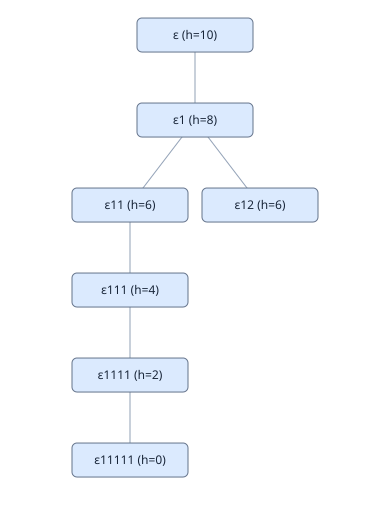

In [8]:
import bz2
nester_game = strahler.Game.from_text(bz2.open(HERE / "nester/Nestern=2.gm.bz2", "rt").read())
found = next(r for r in nester_rows if r["game"] == "Nestern=2.gm" and r["backend"] == "zielonka")
assert found["outcome"] == "complete"
assert strahler.check(nester_game, found["tree"], 0, found["region"]).ok
display(TreeView(found["tree"], game=nester_game, mode="tree"))


## 6. Optional larger rerun
This cell is guarded off. In a repository checkout, enable it to rerun the
historical driver on larger cached Nester games with the real **30 s / 2 GiB**
budget. The driver can download missing archive entries, so it is deliberately
outside the default offline experiment. Choose a separate results file to
preserve the historical CSV.


In [9]:
RUN_LARGE = False
if RUN_LARGE:
    import os
    import subprocess
    import sys
    subprocess.run([sys.executable, "scripts/gen_keiren.py", "run",
                    "--archives", "mlsolver", "--games", "Nestern=", "--timeout", "30",
                    "--memory", "2", "--jobs", "1", "--build-dir", os.environ["STRAHLER_BUILD_DIR"],
                    "--results", "nester-current-results.csv"], cwd=HERE.parent, check=True)
